In [ ]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder,MinMaxScaler,StandardScaler
import seaborn as sns
import numpy as np

In [ ]:

df = pd.read_excel("/content/ML_data (1).xlsx")

In [ ]:
df.head()

,Student_ID,Department,Attendance,Internal_Marks,Study_Hours,Backlogs,Gender,Final_Result
0,101,CSE,85,78.0,12,0,Female,Pass
1,102,IT,62,45.0,5,2,Male,Fail
2,103,CSE,91,88.0,15,0,Female,Pass
3,104,ECE,74,NaN,8,1,Male,Pass
4,105,IT,55,39.0,4,3,Female,Fail


In [ ]:
df.sample(5)

,Student_ID,Department,Attendance,Internal_Marks,Study_Hours,Backlogs,Gender,Final_Result
0,101,CSE,85,78.0,12,0,Female,Pass
4,105,IT,55,39.0,4,3,Female,Fail
1,102,IT,62,45.0,5,2,Male,Fail
2,103,CSE,91,88.0,15,0,Female,Pass
3,104,ECE,74,NaN,8,1,Male,Pass


Feautures


In [ ]:
X = df.drop("Final_Result",axis=1)
X

,Student_ID,Department,Attendance,Internal_Marks,Study_Hours,Backlogs,Gender
0,101,CSE,85,78.0,12,0,Female
1,102,IT,62,45.0,5,2,Male
2,103,CSE,91,88.0,15,0,Female
3,104,ECE,74,NaN,8,1,Male
4,105,IT,55,39.0,4,3,Female


Target

In [ ]:
y=df["Final_Result"]
y

,Final_Result
0,Pass
1,Fail
2,Pass
3,Pass
4,Fail


In [ ]:
df.isnull()

,Student_ID,Department,Attendance,Internal_Marks,Study_Hours,Backlogs,Gender,Final_Result
0,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False
3,False,False,False,True,False,False,False,False
4,False,False,False,False,False,False,False,False


In [ ]:
df.isnull().sum()

,0
Student_ID,0
Department,0
Attendance,0
Internal_Marks,1
Study_Hours,0
Backlogs,0
Gender,0
Final_Result,0


Imputation

In [ ]:
df["Internal_Marks"]=df["Internal_Marks"].fillna(df['Internal_Marks'].mean())
df["Internal_Marks"]

,Internal_Marks
0,78.0
1,45.0
2,88.0
3,62.5
4,39.0


Median Imputation

In [ ]:
df["Internal_Marks"]=df["Internal_Marks"].fillna(df['Internal_Marks'].median())
encoder=LabelEncoder()

Encode

In [ ]:
df["Gender_encoded"]=encoder.fit_transform(df["Gender"])
df[["Gender","Gender_encoded"]]

,Gender,Gender_encoded
0,Female,0
1,Male,1
2,Female,0
3,Male,1
4,Female,0


In [ ]:
encoder.fit_transform(df["Department"])
df["Department"]

,Department
0,CSE
1,IT
2,CSE
3,ECE
4,IT


In [ ]:
pd.get_dummies(df,columns=["Department"])

,Student_ID,Attendance,Internal_Marks,Study_Hours,Backlogs,Gender,Final_Result,Gender_encoded,Department_CSE,Department_ECE,Department_IT
0,101,85,78.0,12,0,Female,Pass,0,True,False,False
1,102,62,45.0,5,2,Male,Fail,1,False,False,True
2,103,91,88.0,15,0,Female,Pass,0,True,False,False
3,104,74,62.5,8,1,Male,Pass,1,False,True,False
4,105,55,39.0,4,3,Female,Fail,0,False,False,True


Normalization - MinMaxScaler

Normalization commonly scales values into a fixed range, often 0–1.

In [ ]:
scaler=MinMaxScaler()
df["Study_Hours_scaled"]=scaler.fit_transform(df[["Study_Hours"]])

In [ ]:
df[["Study_Hours","Study_Hours_scaled"]]

,Study_Hours,Study_Hours_scaled
0,12,0.727273
1,5,0.090909
2,15,1.000000
3,8,0.363636
4,4,0.000000


In [ ]:
std_scaler=StandardScaler()
df["Study_Hrs_std_scaled"]=std_scaler.fit_transform(df[['Study_Hours']])

In [ ]:
df[["Study_Hours","Study_Hours_scaled"]]

,Study_Hours,Study_Hours_scaled
0,12,0.727273
1,5,0.090909
2,15,1.000000
3,8,0.363636
4,4,0.000000


Standardization

In [ ]:
std_scaler=StandardScaler()
df["Study_Hrs_std_scaled"]=std_scaler.fit_transform(df[['Study_Hours']])

Study_Hours

4 5 6 7 8 50

In [ ]:
[4,5,6,7,8,50]

[4, 5, 6, 7, 8, 50]


20000 22000 25000 30000 400000 500000

In [ ]:
np.log1p([20000,22000,25000,30000,400000,50000])

array([ 9.90353755,  9.99884319, 10.1266711 , 10.30898599, 12.89922233,
       10.81979828])

<Axes: ylabel='Count'>

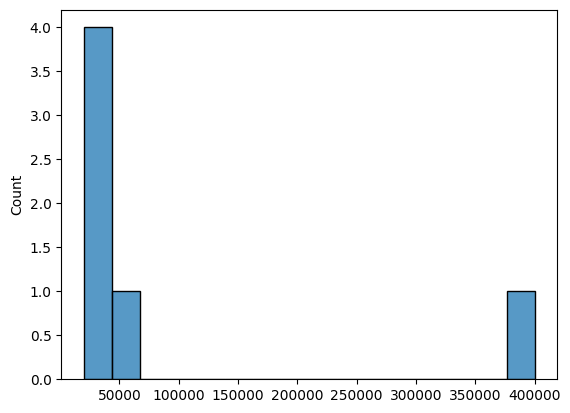

In [ ]:
sns.histplot([20000,22000,25000,30000,400000,50000])


In [ ]:
pd.DataFrame([20000,22000,25000,30000,400000,50000]).skew()

,0
0,2.422044


In [ ]:
pd.DataFrame(np.log1p([20000,22000,25000,30000,400000,500000])).skew()

,0
0,0.943307
